# Week 3 Lab: The Fishery Manager's Dilemma
**SCIE1500 — Analytical Methods for Scientists | Semester 2, 2026**

> **Lab format:** Work in your group. Discuss answers before typing code.
> **Today's session:** ~2 hours | Ask your tutor when stuck.

---
## 🌍 Scientific Scenario

![Schaefer growth curve with harvest lines and MSY point](https://github.com/ahailu95/scie1500-content/blob/main/SCIE1500Materials/Week_3/images/W3_fishery_schaefer.svg?raw=1)

You are a scientific advisor to the **Western Australian Fisheries Authority**. The authority manages a sardine fishery showing signs of overfishing.

Marine biologists use the **Schaefer model** for sardine population growth:

$$G(S) = g \cdot S \cdot \left(1 - \frac{S}{K}\right)$$

| Parameter | Value | Meaning |
|-----------|-------|---------|
| $g$ | 0.4 /yr | Intrinsic growth rate |
| $K$ | 1500 t | Carrying capacity |
| $S$ | 1200 t | Current stock |
| $H$ | 120 t/yr | Current harvest |

> *Is this harvest sustainable?*

---
## 🎯 Group Task & Learning Objectives

| Part | Time | You will be able to... |
|------|------|------|
| A | ~20 min | Use a Schaefer model to compute growth rates and Maximum Sustainable Yield (MSY), explaining bounded growth |
| B | ~25 min | Find equilibrium stock levels by solving a quadratic equation and interpret the stability of two equilibria for current and proposed harvest levels |
| C | ~10 min | Write a policy recommendation based on your analysis |

In [ ]:
# Run this cell first — loads libraries for today's lab
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

---
## Part A: The Schaefer Model (~20 min)

Expanding the Schaefer model:
$$G(S) = 0.4S\left(1 - \frac{S}{1500}\right) = 0.4S - \frac{0.4}{1500}S^2$$

This is a **downward-opening parabola** — growth is zero at $S = 0$ and $S = K$, and peaks at $S^* = K/2$.

In [ ]:
# A.1 — Define the Schaefer growth function and evaluate at three stock levels
g = 0.4      # intrinsic growth rate
K = 1500     # carrying capacity (tonnes)

def G(S):
    'Annual population growth (tonnes/year).'
    return g * S * (1 - S / K)

for S_level in [400, 750, 1200]:
    print(f"G({S_level:4d}) = {G(S_level):.1f} tonnes/year")

S_msy = K / 2
G_msy = G(S_msy)
print(f"\nMSY at S = K/2 = {S_msy:.0f} t  →  G_max = {G_msy:.1f} t/yr")

G( 400) = 117.3 tonnes/year
G( 750) = 150.0 tonnes/year
G(1200) = 96.0 tonnes/year

MSY at S = K/2 = 750 t  →  G_max = 150.0 t/yr


Plot the Schaefer growth curve.

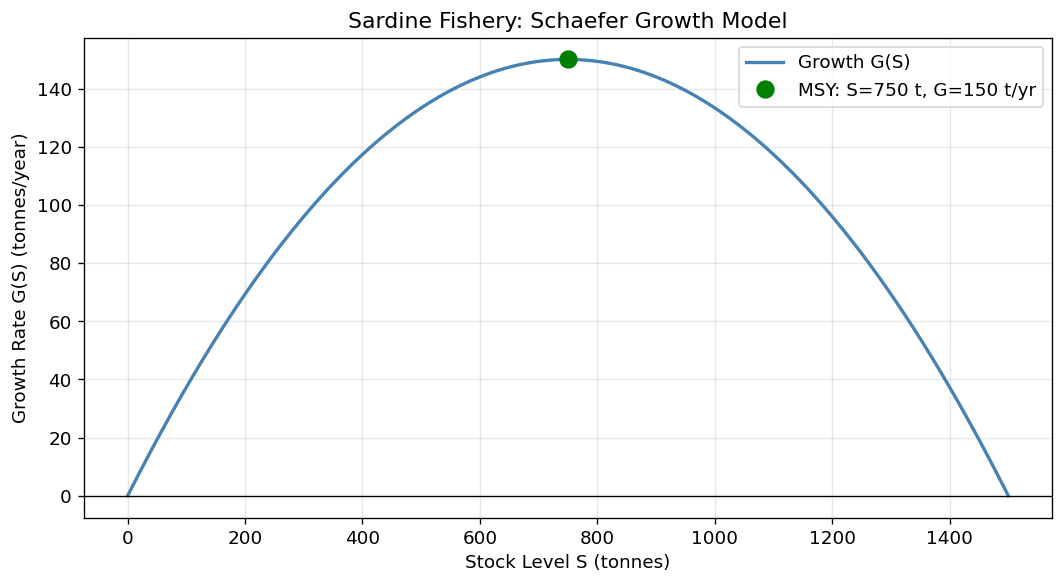

In [ ]:
# A.2 — Plot the Schaefer growth curve
S_vals = np.linspace(0, K, 400)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(S_vals, G(S_vals), "steelblue", lw=2, label="Growth G(S)")
ax.plot(S_msy, G_msy, "go", ms=10, label=f"MSY: S={S_msy:.0f} t, G={G_msy:.0f} t/yr")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Stock Level S (tonnes)")
ax.set_ylabel("Growth Rate G(S) (tonnes/year)")
ax.set_title("Sardine Fishery: Schaefer Growth Model")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

✏️ **Activity A — discuss as a group:**
1. Why does growth peak at $S = K/2$ rather than near the maximum stock level?
2. What does $G(K) = 0$ represent ecologically?
3. At $S = 1200$ t (above $K/2$), is growth increasing or decreasing as stock rises?

```
Answers:
1. ...
2. ...
3. ...
```

---
## Part B: Sustainability Analysis (~25 min)

A harvest $H$ is **sustainable** when growth replaces what is removed: $G(S) \geq H$.

Setting $G(S) = H$ gives the **equilibrium stock levels** — states where stock stays constant.

Rearranging: $\frac{g}{K}S^2 - gS + H = 0$ → solve with the quadratic formula.

In [ ]:
# B.1 — Sustainability check at current stock
S_current = 1200
H = 120    # current harvest (tonnes/year)

G_current = G(S_current)
print(f"G(1200) = {G_current:.1f} t/yr")
print(f"H       = {H} t/yr")
print(f"Sustainable? {G_current >= H}  (need G >= H)")

G(1200) = 96.0 t/yr
H       = 120 t/yr
Sustainable? False  (need G >= H)


Equilibrium stock levels for H = 120: quadratic formula.

In [ ]:
# B.2 — Equilibrium stock levels for H = 120: quadratic formula
a_coef =  g / K
b_coef = -g
c_coef =  H

disc = b_coef**2 - 4 * a_coef * c_coef
S1 = (-b_coef - np.sqrt(disc)) / (2 * a_coef)   # lower (unstable)
S2 = (-b_coef + np.sqrt(disc)) / (2 * a_coef)   # upper (stable)

print(f"Equilibria for H = {H} t/yr:")
print(f"  S₁ = {S1:.1f} t  (lower — unstable collapse threshold)")
print(f"  S₂ = {S2:.1f} t  (upper — stable management target)")
print(f"  Current stock {S_current} t is {'above' if S_current > S1 else 'below'} collapse threshold.")

Equilibria for H = 120 t/yr:
  S₁ = 414.6 t  (lower — unstable collapse threshold)
  S₂ = 1085.4 t  (upper — stable management target)
  Current stock 1200 t is above collapse threshold.


What if harvest increases to 140 t/yr?

In [ ]:
# B.3 — What if harvest increases to 140 t/yr?
H_proposed = 140

c_new = H_proposed
disc_new = b_coef**2 - 4 * a_coef * c_new
if disc_new < 0:
    print(f"H = {H_proposed} t/yr exceeds MSY — no sustainable equilibrium!")
else:
    S1_new = (-b_coef - np.sqrt(disc_new)) / (2 * a_coef)
    S2_new = (-b_coef + np.sqrt(disc_new)) / (2 * a_coef)
    print(f"Equilibria for H = {H_proposed} t/yr:")
    print(f"  S₁ = {S1_new:.1f} t  (collapse threshold rises by {S1_new - S1:.1f} t → riskier)")
    print(f"  S₂ = {S2_new:.1f} t  (stable target falls by {S2 - S2_new:.1f} t → lower stock)")


Equilibria for H = 140 t/yr:
  S₁ = 556.4 t  (collapse threshold rises by 141.8 t → riskier)
  S₂ = 943.6 t  (stable target falls by 141.8 t → lower stock)


The chart below shows both scenarios.

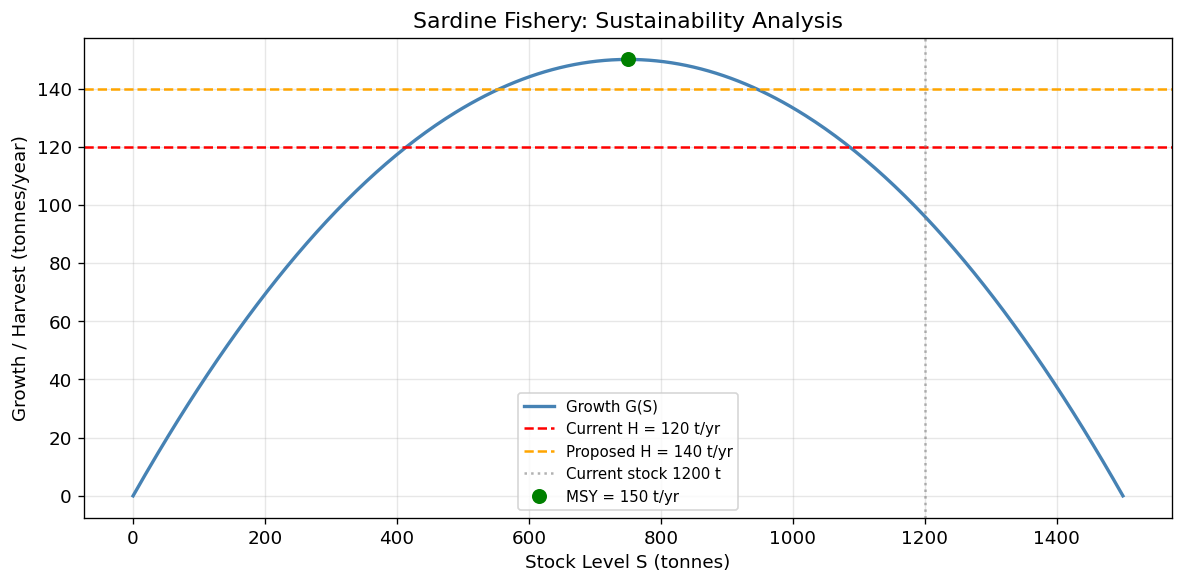

In [ ]:
# Plot both scenarios
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(S_vals, G(S_vals), "steelblue", lw=2, label="Growth G(S)")
ax.axhline(H,          color="red",    ls="--", lw=1.5, label=f"Current H = {H} t/yr")
ax.axhline(H_proposed, color="orange", ls="--", lw=1.5, label=f"Proposed H = {H_proposed} t/yr")
ax.axvline(S_current,  color="gray",   ls=":",  alpha=0.6, label=f"Current stock {S_current} t")
ax.plot(S_msy, G_msy, "go", ms=8, label=f"MSY = {G_msy:.0f} t/yr")
ax.set_xlabel("Stock Level S (tonnes)")
ax.set_ylabel("Growth / Harvest (tonnes/year)")
ax.set_title("Sardine Fishery: Sustainability Analysis")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

✏️ **Activity B:**
1. The current stock (1200 t) is *above* $S_2$ for $H = 120$. What happens to the stock over time?
2. Increasing harvest to 140 t/yr raises the collapse threshold. By how many tonnes?
3. The MSY is 150 t/yr. Why must harvest never exceed MSY?

```python
print("MSY =", G(K/2))
# Answers:
# 1. ...
# 2. ...
# 3. ...
```

---
## Part C: Policy Recommendation (~10 min)

Write a **4–5 sentence recommendation** to the Fisheries Authority:
- Is the current 120 t/yr harvest sustainable?
- Should the proposed 140 t/yr increase be approved?
- What harvest level do you recommend for long-term stability?

```
RECOMMENDATION TO WA FISHERIES AUTHORITY:

...
```

---
## ✅ Lab Wrap-Up

- [ ] Computed $G(S)$ at three stock levels and identified the MSY (Part A)
- [ ] Found equilibrium stock levels for both harvest scenarios (Part B)
- [ ] Written a policy recommendation with specific numbers (Part C)
- [ ] **Groups 3 & 4:** Opened your Presentation Brief (Lab A or Lab B) and started Part A

> 💡 **Key insight:** There are always *two* equilibria — one stable (recovery target), one unstable (collapse threshold). Higher harvest brings these closer together.


---
---
## ✅ Submission Exercise — Batch 1

**Due: Monday 11 August, 11:59 pm — submit on LMS**
**Covers: Weeks 1–3 (functions, exponential models, logistic growth)**

Submit individually. Show full mathematical working for all calculations.
Upload your **completed notebook (.ipynb)** to the LMS — do not submit screenshots.
        

In [ ]:
# Fill in your details before submitting
student_name   = "Gabriel Gaffney"
student_number = "24986508"
print(f"Submission by: {student_name}  |  Student #{student_number}")

Submission by: Gabriel Gaffney  |  Student #24986508



---
### Q1 — Functions and Rates of Change (Week 1)

Southern bluefin tuna population data:

| Year | $t$ (yrs since 2000) | $P(t)$ (thousand fish) |
|------|---------------------|------------------------|
| 2000 | 0  | 90 |
| 2005 | 5  | 82 |
| 2010 | 10 | 71 |
| 2015 | 15 | 65 |
| 2020 | 20 | 61 |

**(a)** Calculate the average rate of change of $P$ over each of the four 5-year intervals. Show working.
        


**Answer (a):**


        

In [ ]:
#2000-2005
(82000-90000) / (5-0)

-1600.0

In [ ]:
#2005-2010
(71000-82000) / (10-5)

-2200.0

In [ ]:
#2010-2015
(65000-71000) / (15-10)

-1200.0

In [ ]:
#2015-2020
 (61000 - 65000) / (20-15)

-800.0


**(b)** Is the decline rate constant? Describe the pattern and what it implies about the shape of $P(t)$.
        

**Answer (b):**
The decline rate is not constant (Linear), however it is also not exponential as the line does not shoot down.
        


**(c)** Plot $P(t)$ from $t = 0$ to $t = 20$. Does a linear model fit this data well? Explain.
        

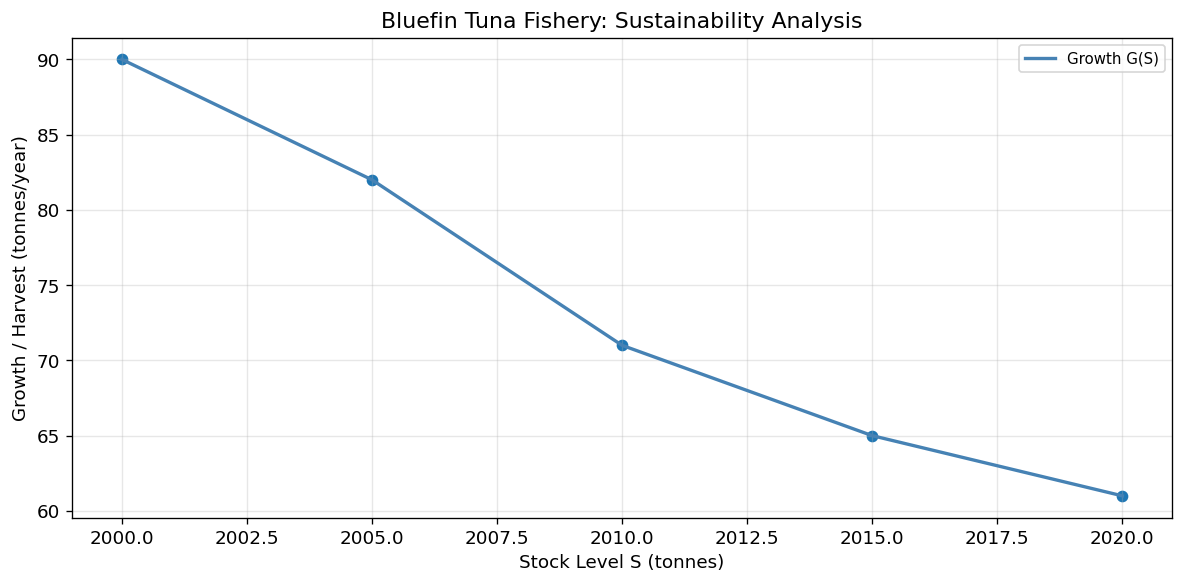

In [ ]:
t = np.array([0,5,10,15,20])
P = np.array([90,82,71,65,61])

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(2000 + t, P, label="Observed Data")
ax.plot(2000 + t, P, "steelblue", lw=2, label="Tuna Population P(t)")

ax.set_xlabel("Year")
ax.set_ylabel("Population P(t) (thousand fish)")
ax.set_title("Southern Bluefin Tuna Population Over Time")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Answer (c) — written interpretation:**

The Bluefin Tuna fishery stock continued to decline throughout the two decades but not in a steady fashion.
        


---
### Q2 — Exponential Decay (Week 2)

A marine toxin degrades as $C(t) = 250\,e^{-0.08t}$ μg/L ($t$ in days).

**(a)** Find the half-life algebraically. Show working using logarithms.
        


**Answer (a):**

Half of 250 is 125 = 0.5

ln(0.5) = ln(e-0.08t)

t=ln(0.5) / -0.08

t= 8.66 days

        


**(b)** The safe-swimming threshold is 5 μg/L. Find the crossing day algebraically, then verify in Python.
        


**Answer (b) — algebraic working:**

(t) 5 = 250 * e-0.08t

5 / 250 = e-0.08t

0.02 = e-0.08t

ln(0.02) / -0.08

t = 48.9 days
        

In [ ]:

# Q2b — Python verification
import numpy as np

def C(t):
    return 250 * np.exp (-0.08 * t)

# Your code here
threshold_concentration = 5

t_crossing = np.log(threshold_concentration / 250) / -0.08

print(f"The toxin concentration reaches {threshold_concentration} μg/L at approximately {t_crossing:.1f} days.")


The toxin concentration reaches 5 μg/L at approximately 48.9 days.



**(c)** Plot $C(t)$ from $t = 0$ to $t = 60$. Mark the threshold as a horizontal dashed line and the crossing day as a vertical marker.
        

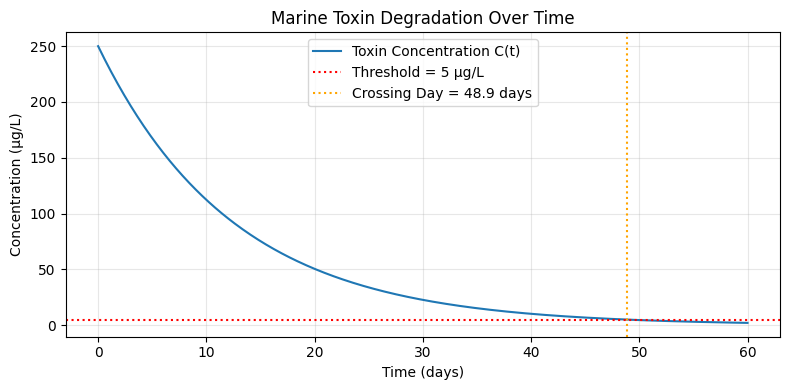

In [ ]:
import matplotlib.pyplot as plt

# Q2c — your code here
# Generate time values from 0 to 60 days
t_vals = np.linspace(0, 60, 500)

fig, ax = plt.subplots(figsize=(8, 4))

# Plot the toxin concentration over time
ax.plot(t_vals, C(t_vals), label="Toxin Concentration C(t)")

# Mark the safe-swimming threshold as a horizontal dashed line
ax.axhline(threshold_concentration, color="red", linestyle=":",
           label=f"Threshold = {threshold_concentration} μg/L")

# Mark the crossing day as a vertical line
ax.axvline(t_crossing, color="orange", linestyle=":",
           label=f"Crossing Day = {t_crossing:.1f} days")

ax.set_xlabel("Time (days)")
ax.set_ylabel("Concentration (μg/L)")
ax.set_title("Marine Toxin Degradation Over Time")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


---
### Q3 — Logistic Fishery (Week 3)

A Carpentaria prawn fishery: $G(S) = 0.5S(1 - S/2000)$.

**(a)** Find the MSY and the stock level at which it occurs. Show the algebraic derivation.
        


**Answer (a):**

G= 0.5

K = 2000

2000 / 2 = 1000 t

0.5 * (1000) * (1- 1000 / 2000)

500 * 0.5

250 t/yr

MSY is 250 tonnes yearly,at a stock level of 1000 tonnes.
        


**(b)** Current stock is 1400 t, harvest is 200 t/yr. Is this sustainable? Justify by computing $G(1400)$.
        


**Answer (b):**

Yes, this is sustainable. The maximum amount that can be harvested a year is 250 t.
        

In [ ]:
# A.1 — Define the Schaefer growth function and evaluate at three stock levels
g = 0.5      # intrinsic growth rate
K = 2000     # carrying capacity (tonnes)

def G(S):
    'Annual population growth (tonnes/year).'
    return g * S * (1 - S / K)

for S_level in [1400]:
    print(f"G({S_level:4d}) = {G(S_level):.1f} tonnes/year")

S_msy = K / 2
G_msy = G(S_msy)
print(f"\nMSY at S = K/2 = {S_msy:.0f} t  →  G_max = {G_msy:.1f} t/yr")

G(1400) = 210.0 tonnes/year

MSY at S = K/2 = 1000 t  →  G_max = 250.0 t/yr



**(c)** Find both equilibrium stock levels for $H = 200$ t/yr using the quadratic formula. Identify which is stable and which is unstable.
        


**Answer (c):**

...write your working here...
        

In [ ]:
a_coef_prawn =  g_prawn / K_prawn
b_coef_prawn = -g_prawn
c_coef_prawn =  H_prawn_q3c

disc_prawn = b_coef_prawn**2 - 4 * a_coef_prawn * c_coef_prawn

if disc_prawn < 0:
    print(f"H = {H_prawn_q3c} t/yr exceeds MSY — no sustainable equilibrium!")
else:
    S1_prawn = (-b_coef_prawn - np.sqrt(disc_prawn)) / (2 * a_coef_prawn)   # lower (unstable)
    S2_prawn = (-b_coef_prawn + np.sqrt(disc_prawn)) / (2 * a_coef_prawn)   # upper (stable)

    print(f"Equilibria for H = {H_prawn_q3c} t/yr:")
    print(f"  S₁ = {S1_prawn:.1f} t  (lower — unstable collapse threshold)")
    print(f"  S₂ = {S2_prawn:.1f} t  (upper — stable management target)")
    print(f"  Current stock {S_current_prawn} t is {'above' if S_current_prawn > S1_prawn else 'below'} collapse threshold.")

Equilibria for H = 200 t/yr:
  S₁ = 552.8 t  (lower — unstable collapse threshold)
  S₂ = 1447.2 t  (upper — stable management target)
  Current stock 1400 t is above collapse threshold.



**(d)** [Written] The manager reduces harvest to 150 t/yr while stock is 1400 t. What happens to the stock over time? Justify from the model.
        


**Answer (d):**

The current stock of 1400 t is well above the 367.5t minimum threshold and below the maximum threshold too. This means that the stock will continue to grow to the S2 mark.
        

In [ ]:

H_new_q3d = 150


a_coef_new_q3d = g_prawn / K_prawn
b_coef_new_q3d = -g_prawn
c_coef_new_q3d = H_new_q3d

disc_new_q3d = b_coef_new_q3d**2 - 4 * a_coef_new_q3d * c_coef_new_q3d

if disc_new_q3d < 0:
    print(f"H = {H_new_q3d} t/yr exceeds MSY — no sustainable equilibrium!")
else:
    S1_new_q3d = (-b_coef_new_q3d - np.sqrt(disc_new_q3d)) / (2 * a_coef_new_q3d)
    S2_new_q3d = (-b_coef_new_q3d + np.sqrt(disc_new_q3d)) / (2 * a_coef_new_q3d)

    print(f"Equilibria for H = {H_new_q3d} t/yr:")
    print(f"  S₁ = {S1_new_q3d:.1f} t  (lower — unstable collapse threshold)")
    print(f"  S₂ = {S2_new_q3d:.1f} t  (upper — stable management target)")


    current_stock = S_current_prawn



Equilibria for H = 150 t/yr:
  S₁ = 367.5 t  (lower — unstable collapse threshold)
  S₂ = 1632.5 t  (upper — stable management target)
